In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv("customer_churn.csv")

In [3]:
df.head()

,customer_id,age,tenure_months,monthly_fee,data_usage_gb,support_calls,late_payments,satisfaction_score,contract_type,internet_type,payment_method,paperless_billing,churn
0,50001,67,26,367.11,24.5,2,2,9.0,Two-Year,DSL,Bank Transfer,Yes,0
1,50002,28,94,536.16,8.8,3,1,4.0,Monthly,Mobile,Bank Transfer,Yes,0
2,50003,19,11,366.06,61.9,1,0,6.0,Monthly,DSL,Credit Card,No,0
3,50004,55,84,506.93,11.9,3,1,7.0,Monthly,Fiber,Automatic Payment,Yes,0
4,50005,39,57,454.48,38.6,2,2,10.0,One-Year,DSL,Bank Transfer,Yes,0


In [5]:
df.shape

(1600, 13)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         1600 non-null   int64  
 1   age                 1600 non-null   int64  
 2   tenure_months       1600 non-null   int64  
 3   monthly_fee         1560 non-null   float64
 4   data_usage_gb       1552 non-null   float64
 5   support_calls       1600 non-null   int64  
 6   late_payments       1600 non-null   int64  
 7   satisfaction_score  1544 non-null   float64
 8   contract_type       1600 non-null   object 
 9   internet_type       1600 non-null   object 
 10  payment_method      1568 non-null   object 
 11  paperless_billing   1600 non-null   object 
 12  churn               1600 non-null   int64  
dtypes: float64(3), int64(6), object(4)
memory usage: 162.6+ KB


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,1600.0,50800.500000,462.024530,50001.0,50400.7500,50800.50,51200.250,51600.00
age,1600.0,46.761875,16.687172,18.0,33.0000,47.00,61.000,75.00
tenure_months,1600.0,60.699375,34.917507,1.0,30.0000,61.00,91.000,120.00
monthly_fee,1560.0,415.002231,114.565044,150.0,334.1675,416.88,495.725,772.47
data_usage_gb,1552.0,43.790593,28.257965,2.0,22.2000,38.25,58.300,180.00
support_calls,1600.0,1.416250,1.191164,0.0,1.0000,1.00,2.000,7.00
late_payments,1600.0,0.695000,0.847747,0.0,0.0000,0.00,1.000,5.00
satisfaction_score,1544.0,6.958549,1.736973,1.0,6.0000,7.00,8.000,10.00
churn,1600.0,0.112500,0.316079,0.0,0.0000,0.00,0.000,1.00


In [11]:
missing_value = df.isnull().sum()

In [12]:
missing_value

customer_id            0
age                    0
tenure_months          0
monthly_fee           40
data_usage_gb         48
support_calls          0
late_payments          0
satisfaction_score    56
contract_type          0
internet_type          0
payment_method        32
paperless_billing      0
churn                  0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [15]:
print(df["churn"].value_counts())

churn
0    1420
1     180
Name: count, dtype: int64


In [17]:
print(
    df["churn"].value_counts(normalize=True) * 100
)

churn
0    88.75
1    11.25
Name: proportion, dtype: float64


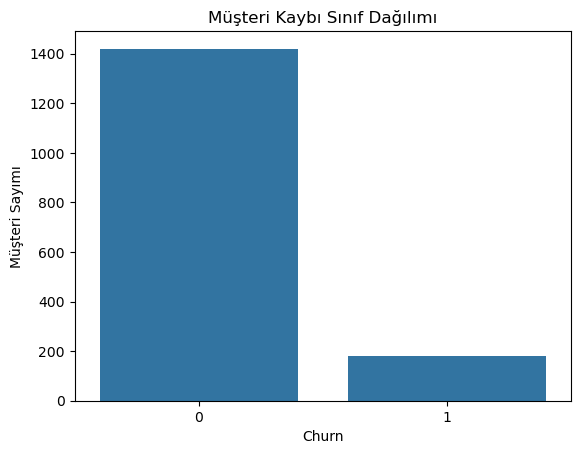

In [21]:
sns.countplot(
    data=df,
    x="churn"
)
plt.title("Müşteri Kaybı Sınıf Dağılımı")
plt.xlabel("Churn")
plt.ylabel("Müşteri Sayımı")
plt.xticks(
    ticks=[0,1],
    label=["Ayrılmadı","Ayrıldı"]
)
plt.show()

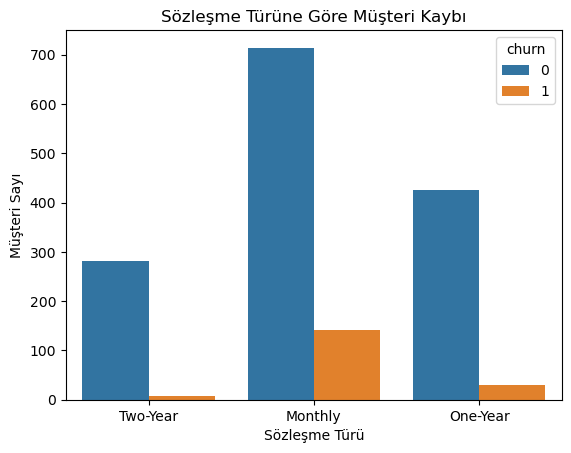

In [25]:
sns.countplot(
    data=df,
    x="contract_type",
    hue="churn"
)
plt.title("Sözleşme Türüne Göre Müşteri Kaybı")
plt.xlabel("Sözleşme Türü")
plt.ylabel("Müşteri Sayı")
plt.show()

In [28]:
contract_churn_rate = (
    df.groupby("contract_type")["churn"].mean().sort_values(ascending=False) * 100
)
print(contract_churn_rate)

contract_type
Monthly     16.588785
One-Year     6.593407
Two-Year     2.768166
Name: churn, dtype: float64


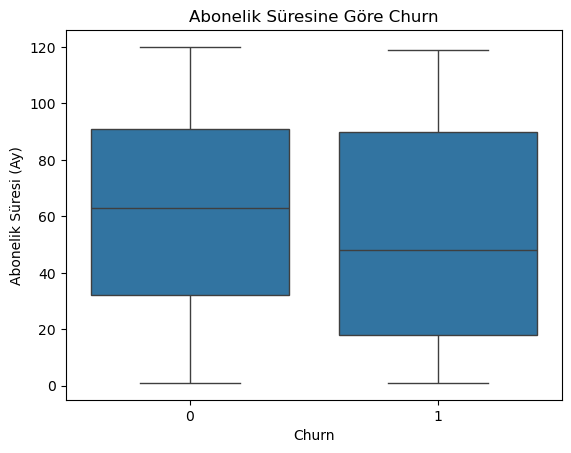

In [31]:
sns.boxplot(
    data=df,
    x="churn",
    y="tenure_months"
)
plt.title("Abonelik Süresine Göre Churn")
plt.xlabel("Churn")
plt.ylabel("Abonelik Süresi (Ay)")
plt.show()

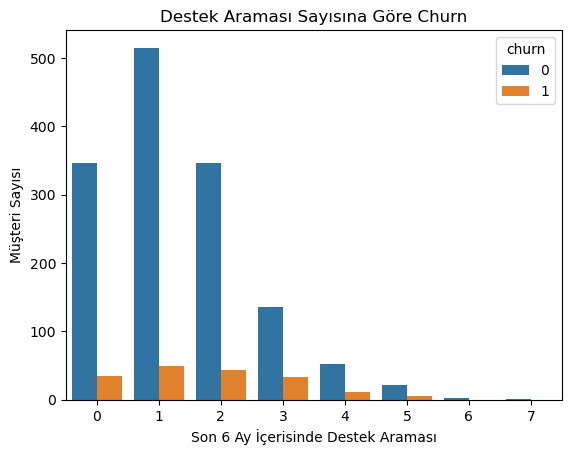

In [32]:
sns.countplot(
    data=df,
    x="support_calls",
    hue="churn"
)
plt.title("Destek Araması Sayısına Göre Churn")
plt.xlabel("Son 6 Ay İçerisinde Destek Araması")
plt.ylabel("Müşteri Sayısı")
plt.show()

In [35]:
numeric_df = df.select_dtypes(include="number")
correlatino_matix = numeric_df.drop(columns=["customer_id"]).corr()

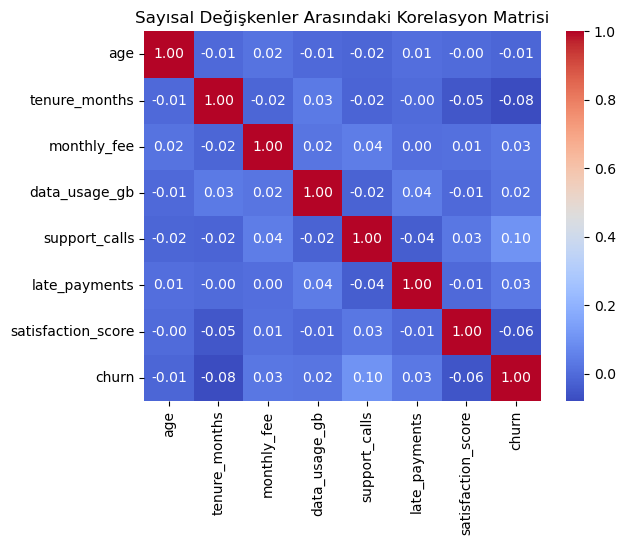

In [36]:
sns.heatmap(correlatino_matix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Sayısal Değişkenler Arasındaki Korelasyon Matrisi")
plt.show()

In [38]:
X = df.drop(columns=["churn","customer_id"])
y=df["churn"]


In [39]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.20,stratify=y)


In [40]:
numeric_features = [
    "age",
    "tenure_months",
    "monthly_fee",
    "data_usage_gb",
    "support_calls",
    "late_payments",
    "satisfaction_score"
]

categorical_features = [
    "contract_type",
    "internet_type",
    "payment_method",
    "paperless_billing"
]

In [41]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median"))
    ]
)

In [44]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [46]:
tree_model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                criterion="gini",
                max_depth=None,
                min_samples_leaf=1,
                min_samples_split=2,
                random_state=42
            )
        )
    ]
)

In [47]:
tree_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
y_pred = tree_model.predict(X_test)
print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0]


In [49]:
y_probability = tree_model.predict_proba(X_test)
print(y_probability[:5])

[[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]


In [50]:
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:",round(accuracy,4))

Accuracy: 0.7844


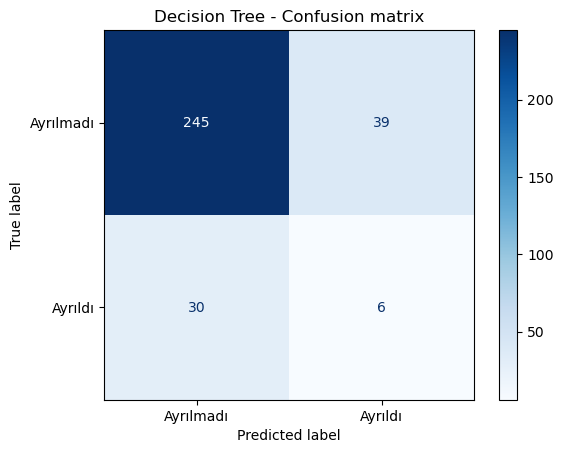

In [51]:
cm = confusion_matrix(y_test,y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ayrılmadı","Ayrıldı"]
).plot(cmap="Blues")
plt.title("Decision Tree - Confusion matrix")
plt.show()